In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

In [2]:
import pandas as pd
from pathlib import Path

df = pd.read_csv(Path("student-mat.csv"), sep=";")
df.columns = df.columns.str.strip()

print(df.columns.tolist())
df.head()

['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,4,6,10,10


In [3]:
print("Column names:")
print(df.columns.tolist())

print("\nData types and non-empty values:")
df.info()

print("\nMissing values in each column:")
print(df.isna().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

Column names:
['school', 'sex', 'age', 'address', 'famsize', 'Pstatus', 'Medu', 'Fedu', 'Mjob', 'Fjob', 'reason', 'guardian', 'traveltime', 'studytime', 'failures', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic', 'famrel', 'freetime', 'goout', 'Dalc', 'Walc', 'health', 'absences', 'G1', 'G2', 'G3']

Data types and non-empty values:
<class 'pandas.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 33 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   school      395 non-null    str  
 1   sex         395 non-null    str  
 2   age         395 non-null    int64
 3   address     395 non-null    str  
 4   famsize     395 non-null    str  
 5   Pstatus     395 non-null    str  
 6   Medu        395 non-null    int64
 7   Fedu        395 non-null    int64
 8   Mjob        395 non-null    str  
 9   Fjob        395 non-null    str  
 10  reason      395 non-null    str  
 11  guardian    395 no

In [4]:
# Remove duplicate rows.
df = df.drop_duplicates().copy()

# Keep the input features and final grade.
model_data = df[["studytime", "G1", "G2", "G3"]].copy()

# Remove rows with missing values.
model_data = model_data.dropna()

In [5]:
X = model_data[["studytime", "G1", "G2"]]
y = model_data["G3"]

In [6]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

model = LinearRegression()
model.fit(X_train, y_train)

print("Model trained.")
print("Intercept:", model.intercept_)
print("Studytime coefficient:", model.coef_[0])

Model trained.
Intercept: -1.9524995494696569
Studytime coefficient: -0.05748965541859541


In [7]:
predictions = model.predict(X_test)

mae = mean_absolute_error(y_test, predictions)
mse = mean_squared_error(y_test, predictions)
rmse = mse ** 0.5
r2 = r2_score(y_test, predictions)

print(f"Mean Absolute Error (MAE): {mae:.2f} grade points")
print(f"Root Mean Squared Error (RMSE): {rmse:.2f} grade points")
print(f"R-squared (R²): {r2:.3f}")

Mean Absolute Error (MAE): 1.27 grade points
Root Mean Squared Error (RMSE): 2.04 grade points
R-squared (R²): 0.797


In [8]:
results = pd.DataFrame({
    "Actual G3": y_test,
    "Predicted G3": predictions
})

results.head(10)

,Actual G3,Predicted G3
78,10,7.264737
371,12,12.235690
248,5,3.395634
55,10,8.199792
390,9,8.366588
223,13,12.837155
42,18,18.967450
234,6,6.381497
316,0,7.207247
116,14,12.670360


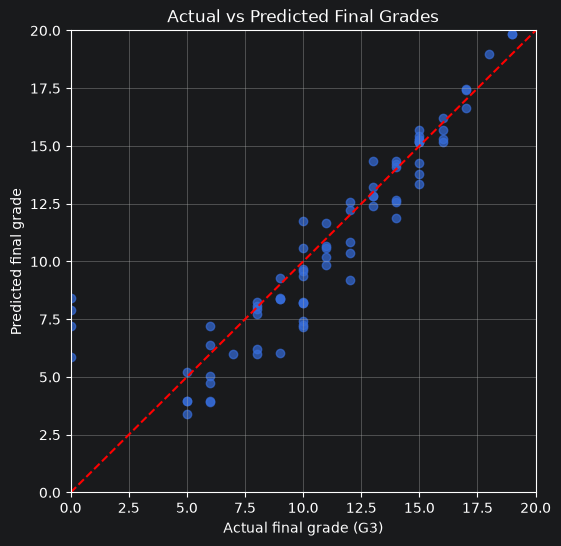

In [9]:
plt.figure(figsize=(6, 6))

plt.scatter(y_test, predictions, alpha=0.7)

# A perfect prediction would fall on this diagonal line.
plt.plot([0, 20], [0, 20], color="red", linestyle="--")

plt.xlabel("Actual final grade (G3)")
plt.ylabel("Predicted final grade")
plt.title("Actual vs Predicted Final Grades")
plt.xlim(0, 20)
plt.ylim(0, 20)
plt.grid(True)
plt.show()